In [1]:
import torch, torch.nn as nn, torch.optim as optim
import torchvision, torchvision.transforms as transforms
from torchvision.models import resnet18
from torch.utils.data import DataLoader
import numpy as np, pandas as pd, matplotlib.pyplot as plt, time
from tqdm import trange, tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# CIFAR-10 stats
mean = (0.4914, 0.4822, 0.4465)
std  = (0.2023, 0.1994, 0.2010)

# Progressive transforms only
def progressive_transform(epoch):
    if epoch < 10:
        return transforms.Compose([
            transforms.Resize(224),
            transforms.RandomHorizontalFlip(),
            transforms.RandomCrop(224, padding=16),
            transforms.ColorJitter(0.2, 0.2, 0.2, 0.1),
            transforms.ToTensor(),
            transforms.Normalize(mean, std)
        ])
    else:
        return transforms.Compose([
            transforms.Resize(224),
            transforms.AutoAugment(transforms.AutoAugmentPolicy.IMAGENET),
            transforms.ToTensor(),
            transforms.RandomErasing(p=0.25),
            transforms.Normalize(mean, std)
        ])

# Test transform
test_tf = transforms.Compose([
    transforms.Resize(224),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Dataset
trainset = torchvision.datasets.CIFAR10(
    "./data", train=True, download=True, transform=progressive_transform(0)
)
testset = torchvision.datasets.CIFAR10(
    "./data", train=False, download=True, transform=test_tf
)

trainloader = DataLoader(trainset, batch_size=128, shuffle=True, num_workers=2)
testloader  = DataLoader(testset, batch_size=100, shuffle=False, num_workers=2)

# Model
def get_model():
    model = resnet18(weights="IMAGENET1K_V1")
    model.fc = nn.Linear(model.fc.in_features, 10)
    return model.to(device)

criterion = nn.CrossEntropyLoss()


Device: cuda


100%|██████████| 170M/170M [00:12<00:00, 13.7MB/s]


In [2]:

def train_epoch(model, optimizer, epoch, progressive):
    start_time = time.time()
    model.train()
    trainset.transform = progressive_transform(epoch) if progressive else baseline_transform()

    correct = total = 0
    loss_sum = 0

    for x, y in trainloader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()

        loss_sum += loss.item()
        _, p = out.max(1)
        total += y.size(0)
        correct += p.eq(y).sum().item()

    epoch_time = time.time() - start_time
    return loss_sum/len(trainloader), 100*correct/total, epoch_time

def evaluate(model):
    model.eval()
    correct = total = 0
    with torch.no_grad():
        for x, y in testloader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            _, p = out.max(1)
            total += y.size(0)
            correct += p.eq(y).sum().item()
    return 100*correct/total

EPOCHS = 20
results = {}

for mode in ["progressive"]:
    print(f"\nTraining {mode.upper()}")
    model = get_model()
    optimizer = optim.SGD(model.parameters(), lr=0.05, momentum=0.9, weight_decay=5e-4)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

    hist = {"train_acc":[], "test_acc":[], "train_loss":[], "epoch_time":[]}

    for epoch in range(EPOCHS):
        loss, train_acc, t = train_epoch(model, optimizer, epoch, progressive=(mode=="progressive"))
        test_acc = evaluate(model)
        scheduler.step()

        hist["train_loss"].append(loss)
        hist["train_acc"].append(train_acc)
        hist["test_acc"].append(test_acc)
        hist["epoch_time"].append(t)

        print(f"Epoch {epoch+1:02d} | "
              f"Time {t:.1f}s | "
              f"Train {train_acc:.2f}% | "
              f"Test {test_acc:.2f}%")

    results[mode] = hist



Training PROGRESSIVE
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 243MB/s]


Epoch 01 | Time 182.6s | Train 76.37% | Test 84.06%
Epoch 02 | Time 185.3s | Train 87.83% | Test 85.89%
Epoch 03 | Time 183.4s | Train 90.04% | Test 88.57%
Epoch 04 | Time 184.1s | Train 91.31% | Test 90.03%
Epoch 05 | Time 183.7s | Train 92.29% | Test 89.19%
Epoch 06 | Time 188.1s | Train 92.76% | Test 91.09%
Epoch 07 | Time 180.8s | Train 93.42% | Test 91.50%
Epoch 08 | Time 182.7s | Train 94.46% | Test 91.45%
Epoch 09 | Time 180.9s | Train 95.31% | Test 90.98%
Epoch 10 | Time 181.7s | Train 95.86% | Test 91.64%
Epoch 11 | Time 90.6s | Train 84.92% | Test 90.56%
Epoch 12 | Time 87.8s | Train 88.83% | Test 92.39%
Epoch 13 | Time 88.4s | Train 91.07% | Test 93.12%
Epoch 14 | Time 91.4s | Train 92.59% | Test 93.72%
Epoch 15 | Time 90.5s | Train 94.16% | Test 94.43%
Epoch 16 | Time 91.2s | Train 95.23% | Test 95.62%
Epoch 17 | Time 90.9s | Train 96.10% | Test 95.70%
Epoch 18 | Time 90.6s | Train 96.56% | Test 95.76%
Epoch 19 | Time 91.2s | Train 97.11% | Test 95.98%
Epoch 20 | Time 90.8s

In [3]:
# ============================================
# BASELINE TRAINING ONLY (ResNet18 on CIFAR-10)
# - uses your transforms/loaders/get_model/criterion
# - trains baseline only
# - prints epoch stats
# - evaluates clean test accuracy
# - saves baseline checkpoint
# ============================================

import torch
import torch.optim as optim
import time
import os

# --- make sure these exist from your earlier cell ---
# device, trainloader, testloader, get_model, criterion

def train_baseline(model, trainloader, optimizer, criterion, epochs=15):
    model.train()
    history = []

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0
        t0 = time.time()

        for images, labels in trainloader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * labels.size(0)
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

        epoch_time = time.time() - t0
        epoch_loss = running_loss / max(total, 1)
        epoch_acc = 100.0 * correct / max(total, 1)

        history.append({
            "epoch": epoch,
            "train_loss": epoch_loss,
            "train_acc": epoch_acc,
            "epoch_time_s": epoch_time
        })

        print(f"Epoch {epoch:02d}/{epochs} | loss={epoch_loss:.4f} | acc={epoch_acc:.2f}% | time={epoch_time:.1f}s")

    return history

@torch.no_grad()
def eval_clean(model, testloader):
    model.eval()
    correct = 0
    total = 0
    for images, labels in testloader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        outputs = model(images)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
    return 100.0 * correct / max(total, 1)

# ---- TRAIN BASELINE ONLY ----
EPOCHS = 20  # change if you want
baseline_model = get_model()

optimizer = optim.SGD(
    baseline_model.parameters(),
    lr=0.05,
    momentum=0.9,
    weight_decay=5e-4
)

baseline_history = train_baseline(
    baseline_model,
    trainloader,
    optimizer,
    criterion,
    epochs=EPOCHS
)

baseline_test_acc = eval_clean(baseline_model, testloader)
print(f"\n✅ Baseline CLEAN test accuracy: {baseline_test_acc:.2f}%")

# ---- SAVE ----
os.makedirs("saved_models", exist_ok=True)
torch.save(baseline_model.state_dict(), "saved_models/baseline_model.pth")
print("✅ Saved: saved_models/baseline_model.pth")


Epoch 01/20 | loss=1.0494 | acc=65.55% | time=87.4s
Epoch 02/20 | loss=0.6090 | acc=79.20% | time=88.2s
Epoch 03/20 | loss=0.5337 | acc=81.64% | time=88.2s
Epoch 04/20 | loss=0.4550 | acc=84.30% | time=87.7s
Epoch 05/20 | loss=0.4345 | acc=85.03% | time=88.1s
Epoch 06/20 | loss=0.4101 | acc=85.76% | time=87.6s
Epoch 07/20 | loss=0.4000 | acc=86.22% | time=87.6s
Epoch 08/20 | loss=0.3826 | acc=86.89% | time=87.5s
Epoch 09/20 | loss=0.3798 | acc=86.70% | time=87.3s
Epoch 10/20 | loss=0.3689 | acc=87.20% | time=87.6s
Epoch 11/20 | loss=0.3545 | acc=87.78% | time=87.8s
Epoch 12/20 | loss=0.3481 | acc=87.96% | time=87.3s
Epoch 13/20 | loss=0.3419 | acc=88.36% | time=87.5s
Epoch 14/20 | loss=0.3398 | acc=88.27% | time=87.3s
Epoch 15/20 | loss=0.3308 | acc=88.77% | time=87.4s
Epoch 16/20 | loss=0.3294 | acc=88.70% | time=87.6s
Epoch 17/20 | loss=0.3161 | acc=88.89% | time=87.5s
Epoch 18/20 | loss=0.3173 | acc=89.04% | time=87.7s
Epoch 19/20 | loss=0.3199 | acc=89.04% | time=88.2s
Epoch 20/20 

In [4]:
import os
os.makedirs("saved_models", exist_ok=True)

torch.save(model.state_dict(), "saved_models/pda_model.pth")
print("PDA model saved!")


PDA model saved!


In [5]:
import os

print("Contents of saved_models/:")
for f in os.listdir("saved_models"):
    print(" -", f)


Contents of saved_models/:
 - pda_model.pth
 - baseline_model.pth


In [6]:
import matplotlib.pyplot as plt
import numpy as np

# -------- BASELINE --------
baseline_epochs = [h["epoch"] for h in baseline_history]
baseline_train_acc = [h["train_acc"] for h in baseline_history]
baseline_train_loss = [h["train_loss"] for h in baseline_history]
baseline_epoch_time = [h["epoch_time_s"] for h in baseline_history]

# baseline test acc is only once (after training)
baseline_test_acc_curve = [baseline_test_acc] * len(baseline_epochs)

# -------- PROGRESSIVE --------
prog_hist = results["progressive"]
prog_epochs = np.arange(1, len(prog_hist["train_acc"]) + 1)


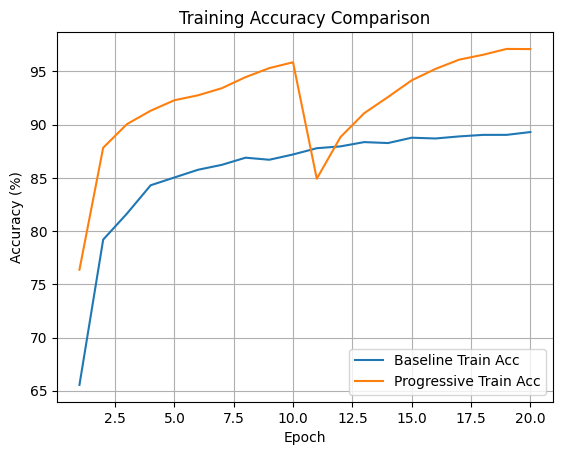

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# -------- BASELINE --------
baseline_epochs = [h["epoch"] for h in baseline_history]
baseline_train_acc = [h["train_acc"] for h in baseline_history]

# -------- PROGRESSIVE --------
prog_hist = results["progressive"]
prog_epochs = np.arange(1, len(prog_hist["train_acc"]) + 1)

plt.figure()
plt.plot(baseline_epochs, baseline_train_acc, label="Baseline Train Acc")
plt.plot(prog_epochs, prog_hist["train_acc"], label="Progressive Train Acc")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training Accuracy Comparison")
plt.legend()
plt.grid(True)
plt.show()


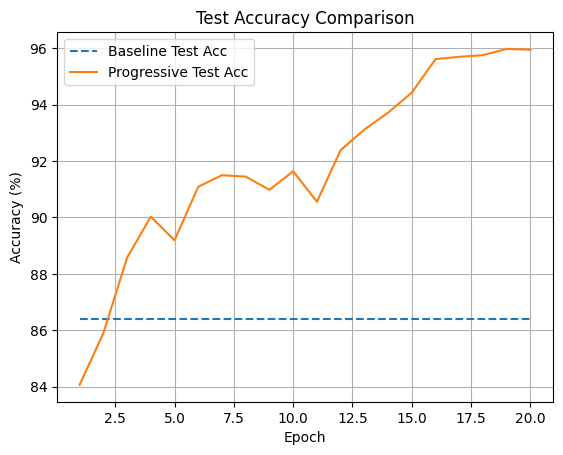

In [8]:
# baseline test accuracy is a single value → draw as flat line
baseline_test_acc_curve = [baseline_test_acc] * len(baseline_epochs)

plt.figure()
plt.plot(baseline_epochs, baseline_test_acc_curve, linestyle="--",
         label="Baseline Test Acc")
plt.plot(prog_epochs, prog_hist["test_acc"],
         label="Progressive Test Acc")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Test Accuracy Comparison")
plt.legend()
plt.grid(True)
plt.show()


In [9]:

import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import pandas as pd

class CIFAR10C(Dataset):
    def __init__(self, root, corruption, severity, transform):
        self.data = np.load(f"{root}/{corruption}.npy")
        self.labels = np.load(f"{root}/labels.npy")

        start = (severity - 1) * 10000
        end   = severity * 10000
        self.data = self.data[start:end]
        self.labels = self.labels[start:end]
        self.transform = transform

    def __len__(self):
        return 10000

    def __getitem__(self, idx):
        img = self.data[idx]
        label = self.labels[idx]
        img = transforms.ToPILImage()(img)
        return self.transform(img), label


cifar10c_tf = transforms.Compose([
    transforms.Resize(224),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])


In [10]:
import os
import urllib.request
import zipfile

# Create folder
os.makedirs("./data", exist_ok=True)

# URL of CIFAR-10-C official zip
url = "https://zenodo.org/record/2535967/files/CIFAR-10-C.tar"
dest_path = "./data/CIFAR-10-C.tar"

# Download if not exists
if not os.path.exists(dest_path):
    print("Downloading CIFAR-10-C (~300MB)...")
    urllib.request.urlretrieve(url, dest_path)
    print("Download complete!")
else:
    print("CIFAR-10-C already downloaded.")

# Extract
if not os.path.exists("./data/CIFAR-10-C"):
    print("Extracting...")
    import tarfile
    with tarfile.open(dest_path) as tar:
        tar.extractall(path="./data")
    print("Extraction done!")
else:
    print("CIFAR-10-C already extracted.")

# Check contents
print("Files:", os.listdir("./data/CIFAR-10-C")[:5])


Download complete!
Extracting...


/tmp/ipykernel_24/2694017947.py:25: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path="./data")


Extraction done!
Files: ['fog.npy', 'jpeg_compression.npy', 'contrast.npy', 'saturate.npy', 'gaussian_blur.npy']


In [11]:
import os, tarfile

tar_path = "/kaggle/working/data/CIFAR-10-C.tar"
out_dir  = "/kaggle/working/data"

assert os.path.exists(tar_path), f"Not found: {tar_path}"

with tarfile.open(tar_path, "r") as tar:
    tar.extractall(path=out_dir)

print("✅ Extracted CIFAR-10-C.tar to:", out_dir)

# show what appeared
print("Contents of /kaggle/working/data:")
print(os.listdir(out_dir))


/tmp/ipykernel_24/3860220643.py:9: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=out_dir)


✅ Extracted CIFAR-10-C.tar to: /kaggle/working/data
Contents of /kaggle/working/data:
['cifar-10-python.tar.gz', 'cifar-10-batches-py', 'CIFAR-10-C', 'CIFAR-10-C.tar']


In [12]:
import glob, os

hits = glob.glob("/kaggle/working/data/**/labels.npy", recursive=True)
print("Found labels.npy:", hits[:3])

CIFAR10C_ROOT = os.path.dirname(hits[0])
print("✅ CIFAR10C_ROOT =", CIFAR10C_ROOT)


Found labels.npy: ['/kaggle/working/data/CIFAR-10-C/labels.npy']
✅ CIFAR10C_ROOT = /kaggle/working/data/CIFAR-10-C


In [13]:
import os
import numpy as np
import torch
import torch.nn.functional as F

# EXACT values from your testloader
MEAN = torch.tensor([0.4914, 0.4822, 0.4465]).view(1,3,1,1)
STD  = torch.tensor([0.2023, 0.1994, 0.2010]).view(1,3,1,1)

def evaluate_cifar10c(model, corruption, severity, batch_size=128, root=None):
    if root is None:
        root = CIFAR10C_ROOT

    x = np.load(os.path.join(root, f"{corruption}.npy"))   # uint8 (50000,32,32,3)
    y = np.load(os.path.join(root, "labels.npy"))          # uint8 (50000,)

    start = (severity - 1) * 10000
    end   = severity * 10000
    x = x[start:end]
    y = y[start:end]

    # to torch [0,1] and NCHW
    x_t = torch.from_numpy(x).permute(0,3,1,2).float() / 255.0
    y_t = torch.from_numpy(y).long()

    # ✅ match testloader: Resize to 224
    x_t = F.interpolate(x_t, size=(224, 224), mode="bilinear", align_corners=False)

    # ✅ match testloader: Normalize with its mean/std
    x_t = (x_t - MEAN) / STD

    loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(x_t, y_t),
        batch_size=batch_size,
        shuffle=False
    )

    model.eval().to(device)
    correct = total = 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            pred = model(xb).argmax(1)
            correct += (pred == yb).sum().item()
            total += yb.size(0)

    return 100.0 * correct / total


In [14]:
# ============================
# LOAD MODELS FROM saved_models
# ============================
baseline_model = get_model().to(device)
baseline_model.load_state_dict(
    torch.load("saved_models/baseline_model.pth", map_location=device)
)
baseline_model.eval()

pda_model = get_model().to(device)
pda_model.load_state_dict(
    torch.load("saved_models/pda_model.pth", map_location=device)
)
pda_model.eval()

print("Baseline and PDA models loaded into memory")


Baseline and PDA models loaded into memory


In [15]:
print("C10-C brightness S1 baseline:", evaluate_cifar10c(baseline_model, "brightness", 1))
print("C10-C brightness S1 PDA:",      evaluate_cifar10c(pda_model, "brightness", 1))


C10-C brightness S1 baseline: 86.4
C10-C brightness S1 PDA: 95.94


In [16]:
# ============================================================
# FINAL EVALUATION CELL:
# - Clean Accuracy (Baseline vs PDA)
# - MCA = Mean Corruption Accuracy (avg over all corruptions & severities)
# - mCE = Mean Corruption Error (avg(100 - acc) over all corruptions & severities)
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# 0) Sanity: models exist
# -----------------------------
assert "baseline_model" in globals(), "baseline_model not found"
assert "pda_model" in globals(), "pda_model not found"
assert "evaluate_cifar10c" in globals(), "evaluate_cifar10c(...) not found in notebook"
assert "evaluate" in globals(), "evaluate(model) not found in notebook"

# -----------------------------
# 1) Helper: call evaluate_cifar10c robustly
# -----------------------------
def _call_eval_cifar10c(fn, model, corr, sev):
    try:
        return fn(model, corr, sev)
    except TypeError:
        pass
    try:
        return fn(model, corr, severity=sev)
    except TypeError:
        pass
    try:
        return fn(model=model, corruption=corr, severity=sev)
    except TypeError as e:
        raise TypeError("evaluate_cifar10c signature mismatch") from e

# -----------------------------
# 2) Clean accuracy
# -----------------------------
clean_acc_baseline = float(evaluate(baseline_model))
clean_acc_pda = float(evaluate(pda_model))

print(f"Clean Accuracy (Baseline): {clean_acc_baseline:.2f}%")
print(f"Clean Accuracy (PDA):      {clean_acc_pda:.2f}%")

# -----------------------------
# 3) CIFAR-10-C settings (STANDARD 15)
# -----------------------------
corruptions = [
    "gaussian_noise", "shot_noise", "impulse_noise",
    "defocus_blur", "glass_blur", "motion_blur", "zoom_blur",
    "snow", "frost", "fog", "brightness",
    "contrast", "elastic_transform", "pixelate", "jpeg_compression"
]
severities = [1, 2, 3, 4, 5]

# -----------------------------
# 4) Evaluate BOTH models
# -----------------------------
records = []

def eval_grid(model_obj, method_name):
    for corr in corruptions:
        for sev in severities:
            acc = float(_call_eval_cifar10c(evaluate_cifar10c, model_obj, corr, sev))
            records.append({
                "Method": method_name,
                "Corruption": corr,
                "Severity": sev,
                "Accuracy (%)": acc
            })

print("\nRunning CIFAR-10-C for Baseline ...")
eval_grid(baseline_model, "Baseline")

print("Running CIFAR-10-C for PDA ...")
eval_grid(pda_model, "PDA")

df = pd.DataFrame(records)
df["Error (%)"] = 100.0 - df["Accuracy (%)"]

# -----------------------------
# 5) Metrics: MCA + mCE
# -----------------------------
mca = df.groupby("Method")["Accuracy (%)"].mean()
mce = df.groupby("Method")["Error (%)"].mean()

print("\nMCA (Mean Corruption Accuracy):")
print(mca)

print("\nmCE (Mean Corruption Error):")
print(mce)

# -----------------------------
# 6) Summary table
# -----------------------------
summary = pd.DataFrame({
    "Clean Accuracy (%)": [clean_acc_baseline, clean_acc_pda],
    "MCA (%)": [mca["Baseline"], mca["PDA"]],
    "mCE (%)": [mce["Baseline"], mce["PDA"]],
}, index=["Baseline", "PDA"])

summary = summary.round(3)
summary


Clean Accuracy (Baseline): 86.41%
Clean Accuracy (PDA):      95.95%

Running CIFAR-10-C for Baseline ...
Running CIFAR-10-C for PDA ...

MCA (Mean Corruption Accuracy):
Method
Baseline    68.762400
PDA         76.949867
Name: Accuracy (%), dtype: float64

mCE (Mean Corruption Error):
Method
Baseline    31.237600
PDA         23.050133
Name: Error (%), dtype: float64


,Clean Accuracy (%),MCA (%),mCE (%)
Baseline,86.41,68.762,31.238
PDA,95.95,76.950,23.050


In [17]:
def pgd_attack(model, x, y, eps=8/255, alpha=2/255, steps=20):
    x_adv = x.clone().detach()
    x_adv += torch.empty_like(x_adv).uniform_(-eps, eps)
    x_adv = torch.clamp(x_adv, 0, 1)

    for _ in range(steps):
        x_adv.requires_grad_(True)
        out = model(x_adv)
        loss = criterion(out, y)
        grad = torch.autograd.grad(loss, x_adv)[0]

        x_adv = x_adv + alpha * grad.sign()
        eta = torch.clamp(x_adv - x, -eps, eps)
        x_adv = torch.clamp(x + eta, 0, 1).detach()

    return x_adv
def cw_attack(model, x, y, c=500, kappa=0, steps=50, lr=0.01):
    model.eval()
    w = torch.zeros_like(x, requires_grad=True)
    optimizer = torch.optim.Adam([w], lr=lr)

    for _ in range(steps):
        adv = torch.tanh(w) / 2 + 0.5
        out = model(adv)

        one_hot = torch.eye(out.size(1)).to(device)[y]
        real = (one_hot * out).sum(dim=1)
        other = ((1 - one_hot) * out - one_hot * 1e4).max(dim=1)[0]

        f = torch.clamp(real - other + kappa, min=0)
        l2 = ((adv - x) ** 2).view(x.size(0), -1).sum(dim=1)
        loss = (l2 + c * f).mean()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    return torch.tanh(w).detach() / 2 + 0.5


In [18]:
@torch.no_grad()
def eval_clean(model):
    model.eval()
    correct = total = 0
    for x, y in testloader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        pred = out.argmax(1)
        correct += pred.eq(y).sum().item()
        total += y.size(0)
    return 100 * correct / total
    
def eval_pgd(model):
    model.eval()
    correct = total = 0
    for x, y in testloader:
        x, y = x.to(device), y.to(device)
        x_adv = pgd_attack(model, x, y)
        with torch.no_grad():
            out = model(x_adv)
            pred = out.argmax(1)
            correct += pred.eq(y).sum().item()
            total += y.size(0)
    return 100 * correct / total 

def eval_cw(model):
    model.eval()
    correct = total = 0
    for x, y in testloader:
        x, y = x.to(device), y.to(device)
        x_adv = cw_attack(model, x, y)
        with torch.no_grad():
            out = model(x_adv)
            pred = out.argmax(1)
            correct += pred.eq(y).sum().item()
            total += y.size(0)
    return 100 * correct / total



In [19]:
# Load models
baseline_model = get_model()
baseline_model.load_state_dict(torch.load("saved_models/baseline_model.pth"))

pda_model = get_model()
pda_model.load_state_dict(torch.load("saved_models/pda_model.pth"))

# Evaluate Baseline
print("Evaluating Baseline...")
b_clean = eval_clean(baseline_model)
b_pgd   = eval_pgd(baseline_model)


# Evaluate PDA
print("Evaluating PDA...")
p_clean = eval_clean(pda_model)
p_pgd   = eval_pgd(pda_model)


# Results
print("\n===== FINAL COMPARISON =====")
print(f"Baseline | Clean: {b_clean:.2f}% | PGD-20: {b_pgd:.2f}% ")
print(f"PDA      | Clean: {p_clean:.2f}% | PGD-20: {p_pgd:.2f}% ")


Evaluating Baseline...
Evaluating PDA...

===== FINAL COMPARISON =====
Baseline | Clean: 86.41% | PGD-20: 4.37% 
PDA      | Clean: 95.95% | PGD-20: 3.03% 


In [20]:
import os, time, tarfile, urllib.request
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Dataset
from torchvision.models import vgg16

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# CIFAR-10 stats (same as your notebook)
mean = (0.4914, 0.4822, 0.4465)
std  = (0.2023, 0.1994, 0.2010)

# ---------- NATURAL (standard augmentation) ----------
def natural_transform():
    return transforms.Compose([
        transforms.Resize(224),
        transforms.RandomCrop(224, padding=16),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])

# ---------- PDA (progressive augmentation like your notebook) ----------
def progressive_transform(epoch: int):
    # You can tweak the schedule if your notebook had different thresholds
    if epoch < 10:
        return transforms.Compose([
            transforms.Resize(224),
            transforms.RandomHorizontalFlip(),
            transforms.RandomCrop(224, padding=16),
            transforms.ColorJitter(0.2, 0.2, 0.2, 0.1),
            transforms.ToTensor(),
            transforms.Normalize(mean, std)
        ])
    else:
        return transforms.Compose([
            transforms.Resize(224),
            transforms.AutoAugment(transforms.AutoAugmentPolicy.IMAGENET),
            transforms.ToTensor(),
            transforms.Normalize(mean, std)
        ])

# ---------- Test transform ----------
test_tf = transforms.Compose([
    transforms.Resize(224),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# ---------- Data ----------
trainset = torchvision.datasets.CIFAR10("./data", train=True, download=True, transform=natural_transform())
testset  = torchvision.datasets.CIFAR10("./data", train=False, download=True, transform=test_tf)

trainloader = DataLoader(trainset, batch_size=128, shuffle=True, num_workers=2, pin_memory=True)
testloader  = DataLoader(testset,  batch_size=128, shuffle=False, num_workers=2, pin_memory=True)

# ---------- VGG16 model ----------
def build_vgg16(num_classes=10, imagenet_pretrained=True):
    model = vgg16(weights="IMAGENET1K_V1" if imagenet_pretrained else None)
    # Replace classifier last layer for CIFAR-10
    model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, num_classes)
    return model.to(device)


Device: cuda


In [21]:
os.makedirs("saved_models", exist_ok=True)

def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    correct, total, total_loss = 0, 0, 0.0
    for x, y in loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * y.size(0)
        pred = logits.argmax(1)
        correct += (pred == y).sum().item()
        total += y.numel()

    return total_loss / total, correct / total

@torch.no_grad()
def eval_clean(model, loader):
    model.eval()
    correct, total = 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        pred = model(x).argmax(1)
        correct += (pred == y).sum().item()
        total += y.numel()
    return correct / total

def train_vgg16(mode="natural", epochs=20, lr=1e-4, weight_decay=5e-4, save_path=None):
    assert mode in ["natural", "pda"]
    model = build_vgg16(imagenet_pretrained=True)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    best_acc = -1.0
    for epoch in range(epochs):
        # swap transform dynamically for PDA (progressively)
        if mode == "pda":
            trainset.transform = progressive_transform(epoch)
        else:
            trainset.transform = natural_transform()

        tr_loss, tr_acc = train_one_epoch(model, trainloader, optimizer, criterion)
        te_acc = eval_clean(model, testloader)

        print(f"[{mode.upper()}] Epoch {epoch+1:02d}/{epochs} | train loss {tr_loss:.4f} | train acc {tr_acc*100:.2f}% | test clean {te_acc*100:.2f}%")

        # save best
        if te_acc > best_acc:
            best_acc = te_acc
            if save_path:
                torch.save(model.state_dict(), save_path)

    print(f"✅ Best clean acc ({mode}): {best_acc*100:.2f}%")
    return model

# ---- Run training (20 epochs) ----
# If you ALREADY have checkpoints, you can skip these two lines.
train_vgg16("natural", epochs=20, save_path="saved_models/vgg16_natural.pth")
train_vgg16("pda",     epochs=20, save_path="saved_models/vgg16_pda.pth")


Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:02<00:00, 221MB/s]


[NATURAL] Epoch 01/20 | train loss 0.4394 | train acc 84.94% | test clean 87.53%
[NATURAL] Epoch 02/20 | train loss 0.2285 | train acc 92.32% | test clean 91.86%
[NATURAL] Epoch 03/20 | train loss 0.1643 | train acc 94.51% | test clean 91.89%
[NATURAL] Epoch 04/20 | train loss 0.1303 | train acc 95.59% | test clean 92.16%
[NATURAL] Epoch 05/20 | train loss 0.1090 | train acc 96.32% | test clean 92.84%
[NATURAL] Epoch 06/20 | train loss 0.0903 | train acc 96.92% | test clean 93.56%
[NATURAL] Epoch 07/20 | train loss 0.0837 | train acc 97.26% | test clean 93.35%
[NATURAL] Epoch 08/20 | train loss 0.0715 | train acc 97.60% | test clean 92.77%
[NATURAL] Epoch 09/20 | train loss 0.0604 | train acc 97.91% | test clean 91.97%
[NATURAL] Epoch 10/20 | train loss 0.0604 | train acc 97.94% | test clean 93.76%
[NATURAL] Epoch 11/20 | train loss 0.0570 | train acc 98.11% | test clean 92.67%
[NATURAL] Epoch 12/20 | train loss 0.0542 | train acc 98.17% | test clean 93.38%
[NATURAL] Epoch 13/20 | trai

VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

In [22]:
# ============================================================
# CIFAR-10-C download + evaluation tables (paper-style)
# ============================================================

# CIFAR-10-C official tar on Zenodo (same as your notebook approach)
url = "https://zenodo.org/record/2535967/files/CIFAR-10-C.tar"
dest_tar = "./data/CIFAR-10-C.tar"
extract_dir = "./data/CIFAR-10-C"

os.makedirs("./data", exist_ok=True)

if not os.path.exists(dest_tar):
    print("Downloading CIFAR-10-C (~300MB)...")
    urllib.request.urlretrieve(url, dest_tar)
    print("Download complete!")
else:
    print("CIFAR-10-C tar already exists.")

if not os.path.exists(extract_dir):
    print("Extracting CIFAR-10-C...")
    with tarfile.open(dest_tar, "r") as tar:
        tar.extractall(path="./data")
    print("Extraction complete!")
else:
    print("CIFAR-10-C already extracted.")

# Corruption list (standard CIFAR-10-C)
corruptions = [
    "gaussian_noise","shot_noise","impulse_noise",
    "defocus_blur","glass_blur","motion_blur","zoom_blur",
    "snow","frost","fog","brightness","spatter",
    "contrast","elastic_transform","pixelate","jpeg_compression"
]

# Group mapping exactly like the corruption benchmark paper grouping
groups = {
    "Noise":   ["gaussian_noise","shot_noise","impulse_noise"],
    "Blur":    ["defocus_blur","glass_blur","motion_blur","zoom_blur"],
    "Weather": ["snow","frost","fog","brightness","spatter"],
    "Digital": ["contrast","elastic_transform","pixelate","jpeg_compression"],
}

# CIFAR-10-C labels
labels = np.load(os.path.join(extract_dir, "labels.npy"))

# Wrap numpy corruption arrays into a Dataset
class CIFAR10C(Dataset):
    def __init__(self, images_np, labels_np, transform):
        self.images = images_np
        self.labels = labels_np
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        # images_np stored as uint8 HWC
        img = self.images[idx]
        img = transforms.ToPILImage()(img)
        x = self.transform(img)
        y = int(self.labels[idx])
        return x, y

@torch.no_grad()
def accuracy(model, loader):
    model.eval()
    correct, total = 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        pred = model(x).argmax(1)
        correct += (pred == y).sum().item()
        total += y.numel()
    return correct / total

def load_model_from_ckpt(ckpt_path):
    model = build_vgg16(imagenet_pretrained=False)
    state = torch.load(ckpt_path, map_location="cpu")
    if isinstance(state, dict) and "state_dict" in state:
        state = state["state_dict"]
    elif isinstance(state, dict) and "model_state_dict" in state:
        state = state["model_state_dict"]
    state = {k.replace("module.", ""): v for k, v in state.items()}
    model.load_state_dict(state, strict=True)
    model.eval()
    return model

# Load both models
natural_model = load_model_from_ckpt("saved_models/vgg16_natural.pth")
pda_model     = load_model_from_ckpt("saved_models/vgg16_pda.pth")

# Clean accuracy (paper reports clean + corruption robustness)
clean_nat = accuracy(natural_model, testloader)
clean_pda = accuracy(pda_model, testloader)
print(f"Clean Acc | Natural: {clean_nat*100:.2f}% | PDA: {clean_pda*100:.2f}%")

# Evaluate all corruptions x severities
records = []

def eval_cifar10c_grid(model, method_name):
    for corr in corruptions:
        corr_path = os.path.join(extract_dir, f"{corr}.npy")
        if not os.path.exists(corr_path):
            print("Missing:", corr_path)
            continue

        images = np.load(corr_path)  # shape (50000, 32, 32, 3)
        # CIFAR-10-C: 5 severities, each chunk is 10,000 images
        for sev in range(1, 6):
            start = (sev - 1) * 10000
            end   = sev * 10000

            ds = CIFAR10C(images[start:end], labels[start:end], transform=test_tf)
            dl = DataLoader(ds, batch_size=128, shuffle=False, num_workers=2, pin_memory=True)

            acc = accuracy(model, dl) * 100.0
            records.append({
                "Method": method_name,
                "Corruption": corr,
                "Severity": sev,
                "Accuracy (%)": acc
            })

print("\nRunning CIFAR-10-C for Natural ...")
eval_cifar10c_grid(natural_model, "Natural")

print("Running CIFAR-10-C for PDA ...")
eval_cifar10c_grid(pda_model, "PDA")

df = pd.DataFrame(records)
df["Error (%)"] = 100.0 - df["Accuracy (%)"]

# ---- Table 1: Summary (Clean + Mean Corruption Acc + Mean Error) ----
mean_corr = df.groupby(["Method"])["Accuracy (%)"].mean()
mean_err  = df.groupby(["Method"])["Error (%)"].mean()

summary = pd.DataFrame({
    "Clean Acc (%)": [clean_nat*100, clean_pda*100],
    "Mean Corruption Acc (%)": [mean_corr["Natural"], mean_corr["PDA"]],
    "Mean Corruption Error (%)": [mean_err["Natural"], mean_err["PDA"]],
}, index=["Natural", "PDA"])

# ---- Table 2: Per-corruption (mean over severities) ----
per_corr = df.groupby(["Method", "Corruption"])["Accuracy (%)"].mean().reset_index()
per_corr_pivot = per_corr.pivot(index="Corruption", columns="Method", values="Accuracy (%)").sort_index()

# ---- Table 3: Grouped (Noise/Blur/Weather/Digital) ----
group_rows = []
for method in ["Natural", "PDA"]:
    for gname, corr_list in groups.items():
        sub = df[(df["Method"] == method) & (df["Corruption"].isin(corr_list))]
        group_rows.append({
            "Method": method,
            "Group": gname,
            "Acc (%)": sub["Accuracy (%)"].mean()
        })
group_df = pd.DataFrame(group_rows).pivot(index="Group", columns="Method", values="Acc (%)")

print("\n================= SUMMARY (like paper) =================")
display(summary)

print("\n============= PER-CORRUPTION (mean over severities) =============")
display(per_corr_pivot)

print("\n============= GROUPED (Noise/Blur/Weather/Digital) =============")
display(group_df)

# Save tables (same idea as your notebook)
os.makedirs("outputs", exist_ok=True)
summary.to_csv("outputs/vgg16_summary_natural_vs_pda.csv")
per_corr_pivot.to_csv("outputs/vgg16_per_corruption_natural_vs_pda.csv")
group_df.to_csv("outputs/vgg16_grouped_natural_vs_pda.csv")
df.to_csv("outputs/vgg16_all_cifar10c_long.csv", index=False)

print("\n✅ Saved tables to outputs/:")
print(" - outputs/vgg16_summary_natural_vs_pda.csv")
print(" - outputs/vgg16_per_corruption_natural_vs_pda.csv")
print(" - outputs/vgg16_grouped_natural_vs_pda.csv")
print(" - outputs/vgg16_all_cifar10c_long.csv")


CIFAR-10-C tar already exists.
CIFAR-10-C already extracted.
Clean Acc | Natural: 93.76% | PDA: 93.69%

Running CIFAR-10-C for Natural ...
Running CIFAR-10-C for PDA ...

================= SUMMARY (like paper) =================


,Clean Acc (%),Mean Corruption Acc (%),Mean Corruption Error (%)
Natural,93.76,68.691875,31.308125
PDA,93.69,72.908125,27.091875



============= PER-CORRUPTION (mean over severities) =============


Method,Natural,PDA
Corruption,,
brightness,91.398,92.844
contrast,76.772,89.078
defocus_blur,84.772,86.116
elastic_transform,81.474,81.568
fog,88.520,90.530
frost,77.910,77.830
gaussian_noise,23.400,34.826
glass_blur,42.608,37.274
impulse_noise,21.140,53.208



============= GROUPED (Noise/Blur/Weather/Digital) =============


Method,Natural,PDA
Group,,
Blur,72.238500,72.391000
Digital,76.967000,79.374500
Noise,26.453333,45.148667
Weather,84.577600,84.804400



✅ Saved tables to outputs/:
 - outputs/vgg16_summary_natural_vs_pda.csv
 - outputs/vgg16_per_corruption_natural_vs_pda.csv
 - outputs/vgg16_grouped_natural_vs_pda.csv
 - outputs/vgg16_all_cifar10c_long.csv
